In [1]:
%matplotlib widget

In [11]:
%%capture
from ocelot import *
from ocelot.gui import *
import matplotlib.pyplot as plt
import numpy as np
from felarc.simple_tba import get_isochronous_arc_dispersion_condition, get_quad_strengths, ArcDefinition, make_arc_to_inner_dipole_start, make_arc
from felarc.t20 import ARC_ANGLE_RAD

The T20 arc comprises a $>6°$ bend.  We start with the simplest isochronous lattice: three identical dipoles, with a total bending angle equal to the 6° we are after.  We also choose a 3m dipole on the basis that in Nina's design we covered the $6°$ in 9m of dipole.

In [17]:
DIPOLE_ANGLE = ARC_ANGLE_RAD / 3
DIPOLE_LENGTH = 3
dx, dxp = get_isochronous_arc_dispersion_condition(dipole_length=DIPOLE_LENGTH, dipole_angle=DIPOLE_ANGLE)

In [18]:
print(dx, dxp)

-0.0261740907458337 -0.01746038085732892


In [19]:
ad = ArcDefinition(dipole_length=DIPOLE_LENGTH, dipole_angle=DIPOLE_ANGLE, l1=1., l2=1, l3=1., qlength=1., k11=1, k12=-1)
mlat = make_arc_to_inner_dipole_start(ad)

In [20]:
k11, k12 = get_quad_strengths(ad)

initial value: x =  [-1, 1]
Optimization terminated successfully.
         Current function value: 2858.766871
         Iterations: 76
         Function evaluations: 143


In [8]:
ad.k11 = k11
ad.k12 = k12
print(ad)
mlat = make_arc_to_inner_dipole_start(ad)

ArcDefinition(dipole_length=1.0, dipole_angle=0.1, l1=1.0, l2=1, l3=1.0, qlength=1.0, k11=np.float64(1.030391851570398), k12=np.float64(-0.49261417800073093))


In [9]:
twiss0 = Twiss(beta_x=20, beta_y=100)
twisses = twiss(mlat, twiss0)
print(twisses[-1].Dx, twisses[-1].Dxp)

-0.02495424634492275 -0.05016663858565757


[<SBend: name=ID_13199728_ at 0x12735e9f0>, <Drift: name=ID_79355437_ at 0x127389d00>, <Quadrupole: name=ID_34819071_ at 0x127389ee0>, <Drift: name=ID_90135122_ at 0x127388170>, <Quadrupole: name=ID_9030668_ at 0x127389f40>, <Drift: name=ID_30849936_ at 0x127389e50>]
0.0016658255404731796
-0.02495424634492275 -0.05016663858565757


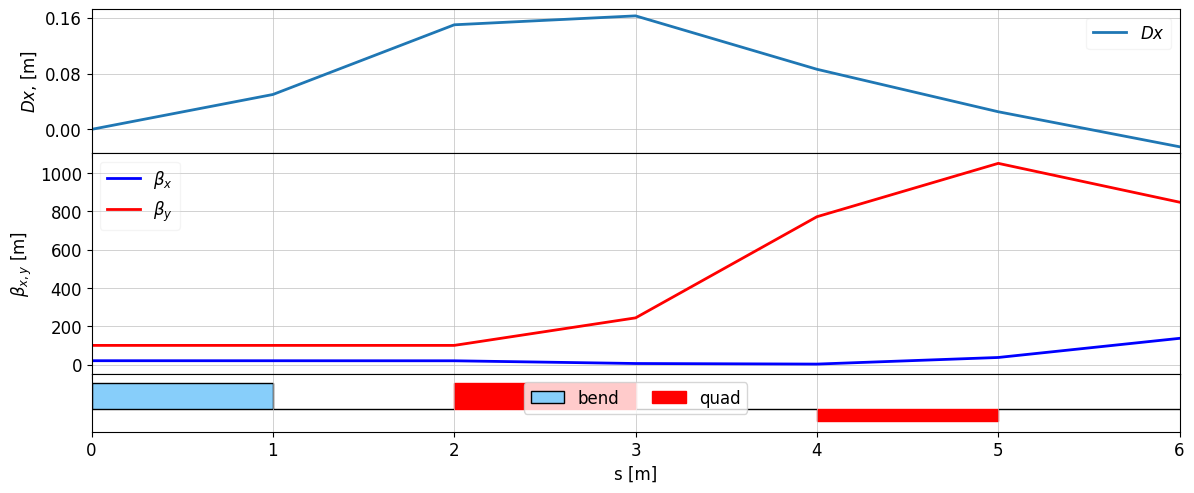

In [10]:
mlat = make_arc_to_inner_dipole_start(ad)
print(mlat.sequence)
_, R, _ = mlat.transfer_maps(energy=14)
print(R[4,5])
twiss0 = Twiss(beta_x=20, beta_y=100)
twisses = twiss(mlat, twiss0)
print(twisses[-1].Dx, twisses[-1].Dxp)
plot_opt_func(mlat, twisses)

In [87]:
print(twisses[-1])

emit_x  = 0.0
emit_y  = 0.0
emit_xn  = 0.0
emit_yn  = 0.0
beta_x  = 136.93743024442833
beta_y  = 848.1179831133418
alpha_x = -65.86163041687928
alpha_y = 96.00507820668655
Dx      = -0.02495424634492275
Dy      = 0.0
Dxp     = -0.05016663858565757
Dyp     = 0.0
mux     = 3.171383121376254
muy     = 0.0319421974644162
nu_x    = 0.5047413002052351
nu_y    = 0.0050837586196792435
E       = 0.0
s        = 6.0

